# RMIT_SGS_Sigma69_C1 — DistilBERT multilingual + QLoRA v2

Mở notebook này trên **Colab GPU**, chạy từ đầu trong runtime mới sau khi đã lưu kết quả cũ.
Upload ZIP dữ liệu ở mục 3, hoặc chọn `DATA_MODE="path"` để dùng thư mục Drive.

**Bản đã chạy:** validation Macro F1 `0.886366`, public `0.87` do người dùng báo.
Lỗi lớn nhất: 98 mẫu BENIGN bị đoán JAILBREAK; tiếng Bồ Đào Nha đạt `0.836839`.
Bản gốc có output được giữ trong `notebooks/archive/RMIT_SGS_Sigma69_C1_Colab_baseline_087.ipynb` của repo.

**Bản v2:** head-tail 512 token; class weights căn bậc hai; LoRA r32 trên attention + FFN;
tối đa 5 epoch; FP16 trên T4; nhánh TF-IDF ký tự + SVM học từ train; chọn ensemble/bias bằng validation.
Mục tiêu `0.95` **chưa được kiểm chứng**. Kết quả CPU thăm dò không phải điểm Kaggle.

Mặc định chỉ train một DistilBERT. Đặt `ENABLE_LEXICAL_BRANCH=False` nếu muốn chỉ dùng QLoRA.
Nhánh SVM không dùng pretrained model/dữ liệu ngoài. Luôn đối chiếu Rules hiện hành của cuộc thi.
Test chỉ dùng inference. Các checkpoint được chọn theo Macro F1 chưa hiệu chỉnh.

Cuối notebook tạo `/content/submission.csv` và ZIP artifacts. Tải bằng panel **Files → Download**;
không tự động mở hai lượt tải trình duyệt. Việc nộp/lưu Kaggle Notebook vẫn theo quy trình của đội.


## 1. Cài dependencies

Giữ bộ Transformers/PEFT/bitsandbytes của lần chạy cũ và pin scikit-learn theo baseline.
Nếu cell yêu cầu restart, chỉ restart sau khi đã tải/lưu artifacts của phiên cũ; chạy lại từ đầu.


In [1]:
import os
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

PINS = {
    "transformers": "4.57.6",
    "peft": "0.17.1",
    "accelerate": "1.10.1",
    "bitsandbytes": "0.48.1",
    "scikit-learn": "1.6.1",
}
loaded_conflicts = []
for package, wanted in PINS.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    module_name = "sklearn" if package == "scikit-learn" else package
    if module_name in sys.modules and installed != wanted:
        loaded_conflicts.append(package)

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--quiet",
    *[f"{name}=={release}" for name, release in PINS.items()],
    "huggingface-hub>=0.34,<1",
    "pandas>=2.2,<3", "joblib>=1.2,<2",
    "matplotlib>=3.8,<4", "safetensors>=0.4.3",
])
if loaded_conflicts:
    raise RuntimeError(
        "Da doi thu vien dang duoc import: " + ", ".join(loaded_conflicts)
        + ". Chon Runtime > Restart session, sau do chay lai tu dau."
    )
print("Dependencies ready. PyTorch CUDA cua Colab duoc giu nguyen.")


Dependencies ready. PyTorch CUDA cua Colab duoc giu nguyen.


## 2. Cấu hình

Giữ **DATA_MODE = "upload"** để chọn CSV/ZIP từ máy. Nếu dữ liệu đã ở Colab, chọn **"path"** và sửa DATA_DIR. Muốn dùng Google Drive, bật MOUNT_DRIVE và đặt DATA_DIR hoặc OUTPUT_ROOT dưới thư mục Drive.

TRAIN_BATCH_SIZE × GRAD_ACCUM_STEPS = effective batch size. Nếu hết VRAM, giảm batch từ 8 xuống 4 và tăng accumulation từ 4 lên 8. LONG_TEXT_MODE có thể đổi từ **"head"** sang **"head_tail"** cho một thí nghiệm riêng.


In [2]:
# Chinh cau hinh truoc khi chay. V2 can train lai, khong dung outputs cua ban cu.
DATA_MODE = "upload"                      # "upload" hoac "path"
DATA_DIR = "/content/rmit-hackathon-2026"
MOUNT_DRIVE = False
OUTPUT_ROOT = "/content/rmit_c1_runs"       # Doi sang Drive neu muon giu checkpoints
MODEL_SOURCE = "distilbert/distilbert-base-multilingual-cased"
MODEL_REVISION = "45c032ab32cc946ad88a166f7cb282f58c753c2e"
RUN_NAME = "distilmbert_qlora_v2"

SEED = 42                                  # Seed huan luyen
SPLIT_SEED = 42                            # Giu split baseline khi doi SEED
VAL_SIZE = 0.10
MAX_LENGTH = 512
LONG_TEXT_MODE = "head_tail"               # "head" hoac "head_tail"
EPOCHS = 5
LEARNING_RATE = 1e-4
TRAIN_BATCH_SIZE = 8
EVAL_BATCH_SIZE = 16
GRAD_ACCUM_STEPS = 4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
EARLY_STOPPING_PATIENCE = 2
USE_CLASS_WEIGHTS = True
CLASS_WEIGHT_POWER = 0.5                    # 0: CE, 0.5: sqrt, 1: inverse frequency
GRADIENT_CHECKPOINTING = True

LORA_R = 32
LORA_ALPHA = 64
LORA_DROPOUT = 0.05
LORA_TARGETS = ["q_lin", "k_lin", "v_lin", "out_lin", "lin1", "lin2"]
HEAD_MODULES = ["pre_classifier", "classifier"]
LABELS = ["BENIGN", "JAILBREAK", "PROMPT_INJECTION"]
LABEL2ID = {label: index for index, label in enumerate(LABELS)}
ID2LABEL = {index: label for label, index in LABEL2ID.items()}
LANGUAGES = ["pt", "fr", "it", "en"]

ENABLE_LEXICAL_BRANCH = True
LEXICAL_MAX_FEATURES = 300000
LEXICAL_C = 2.0
LEXICAL_GLOBAL_WEIGHT = 0.5                # 0.5 global + 0.5 theo ngon ngu
MIN_POSTPROCESS_GAIN = 0.002               # Guard bang cross-fit tren validation

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

assert DATA_MODE in {"upload", "path"}
assert LONG_TEXT_MODE in {"head", "head_tail"}
assert 0 < VAL_SIZE < 1
assert 8 <= MAX_LENGTH <= 512 and MAX_LENGTH % 8 == 0
assert TRAIN_BATCH_SIZE > 0 and GRAD_ACCUM_STEPS > 0
assert EPOCHS >= 1 and 0 <= CLASS_WEIGHT_POWER <= 1
assert 0 <= LEXICAL_GLOBAL_WEIGHT <= 1
print("Effective batch size:", TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS)


Effective batch size: 32


In [3]:
import gc
import io
import json
import hashlib
import shutil
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import bitsandbytes as bnb
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)
from transformers import (
    AutoConfig, AutoTokenizer, AutoModelForSequenceClassification,
    BitsAndBytesConfig, DataCollatorWithPadding, Trainer,
    TrainingArguments, EarlyStoppingCallback, set_seed,
)
from peft import LoraConfig, TaskType, get_peft_model, prepare_model_for_kbit_training
from IPython.display import display, FileLink

if not torch.cuda.is_available():
    raise RuntimeError("Can GPU CUDA: Runtime > Change runtime type > GPU, roi chay lai.")
if torch.cuda.device_count() != 1:
    raise RuntimeError("Notebook yeu cau mot GPU. Restart runtime de CUDA_VISIBLE_DEVICES co hieu luc.")

set_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
# T4 (capability 7.5) khong co native BF16, du PyTorch co the cho phep emulation.
GPU_CAPABILITY = torch.cuda.get_device_capability(0)
USE_BF16 = GPU_CAPABILITY[0] >= 8 and torch.cuda.is_bf16_supported()
COMPUTE_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
PACKAGE_VERSIONS = {
    name: version(name)
    for name in ["torch", "transformers", "peft", "accelerate", "bitsandbytes",
                 "huggingface-hub", "numpy", "pandas", "scikit-learn", "safetensors", "joblib"]
}
for package, wanted in PINS.items():
    if PACKAGE_VERSIONS[package] != wanted:
        raise RuntimeError(f"Sai version {package}; restart runtime va chay lai cell cai dat.")

DATA_PATH = Path(DATA_DIR)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR = Path(OUTPUT_ROOT) / f"{RUN_NAME}_{RUN_ID}"
ARTIFACT_DIR = RUN_DIR / "artifacts"
ADAPTER_DIR = ARTIFACT_DIR / "adapter"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=False)

print("Python:", sys.version)
print("GPU capability:", GPU_CAPABILITY)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
print("Compute dtype:", COMPUTE_DTYPE)
print("Output:", RUN_DIR)
display(pd.DataFrame(PACKAGE_VERSIONS.items(), columns=["package", "version"]))


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
GPU capability: (7, 5)
GPU: Tesla T4
VRAM (GiB): 14.6
Compute dtype: torch.float16
Output: /content/rmit_c1_runs/distilmbert_qlora_v2_20261022T061310_050585Z


,package,version
0,torch,2.11.0+cu130
1,transformers,4.57.6
2,peft,0.17.1
3,accelerate,1.10.1
4,bitsandbytes,0.48.1
5,huggingface-hub,0.36.2
6,numpy,2.1.3
7,pandas,2.2.3
8,scikit-learn,1.6.1
9,safetensors,0.8.0


## 3. Upload dữ liệu

Chọn cả ba CSV trong một lần hoặc upload ZIP từ Kaggle. Nếu dùng ZIP, notebook chỉ lấy ba CSV có tên đúng, kể cả khi chúng nằm trong thư mục con. Không cần Kaggle token và không tải dữ liệu từ GitHub.


In [4]:
EXPECTED_FILES = {"train.csv", "test.csv", "sample_submission.csv"}

if DATA_MODE == "upload":
    from google.colab import files
    uploaded = files.upload()
    selected = {}

    def add_csv(name, payload):
        if name in selected:
            raise ValueError(f"Trung file {name} trong lan upload. Chi chon mot ban moi file.")
        selected[name] = payload

    for upload_name, payload in uploaded.items():
        filename = Path(upload_name).name
        if filename in EXPECTED_FILES:
            add_csv(filename, payload)
        elif filename.lower().endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                for member in archive.infolist():
                    name = Path(member.filename).name
                    if not member.is_dir() and name in EXPECTED_FILES:
                        add_csv(name, archive.read(member))

    missing = EXPECTED_FILES - set(selected)
    if missing:
        raise ValueError(f"Upload thieu {sorted(missing)}. Chay lai cell va chon ca ba CSV/ZIP.")
    DATA_PATH.mkdir(parents=True, exist_ok=True)
    for name, payload in selected.items():
        (DATA_PATH / name).write_bytes(payload)
    del uploaded, selected

missing = [name for name in EXPECTED_FILES if not (DATA_PATH / name).is_file()]
if missing:
    raise FileNotFoundError(f"Khong tim thay {missing} trong {DATA_PATH}. Kiem tra DATA_DIR.")
print("Data directory:", DATA_PATH)


Saving rmit-hackathon-2026.zip to rmit-hackathon-2026 (1).zip
Data directory: /content/rmit-hackathon-2026


In [5]:
def load_csv(name):
    # Giu nguyen text va ID, khong bien chuoi "NA" thanh gia tri thieu.
    return pd.read_csv(DATA_PATH / name, dtype=str, keep_default_na=False, encoding="utf-8-sig")

train_df = load_csv("train.csv")
test_df = load_csv("test.csv")
sample_df = load_csv("sample_submission.csv")

def validate_frame(frame, name, columns, expected_rows):
    if list(frame.columns) != columns:
        raise ValueError(f"{name}: can cot {columns}; nhan duoc {list(frame.columns)}.")
    if len(frame) != expected_rows:
        raise ValueError(f"{name}: can {expected_rows} dong; nhan duoc {len(frame)}.")
    if frame["id"].isna().any() or frame["id"].str.strip().eq("").any() or not frame["id"].is_unique:
        raise ValueError(f"{name}: ID rong hoac trung.")
    for column in ["text", "language"]:
        if column in frame and (
            frame[column].isna().any() or frame[column].str.strip().eq("").any()
        ):
            raise ValueError(f"{name}: {column} rong.")
    if "language" in frame and not set(frame["language"]).issubset(LANGUAGES):
        raise ValueError(f"{name}: language ngoai mien {LANGUAGES}.")

validate_frame(train_df, "train.csv", ["id", "text", "language", "label"], 14000)
validate_frame(test_df, "test.csv", ["id", "text", "language"], 6000)
validate_frame(sample_df, "sample_submission.csv", ["id", "label"], 6000)
if set(train_df["label"]) != set(LABELS):
    raise ValueError("Train phai chua du ba nhan chinh xac.")
if set(sample_df["id"]) != set(test_df["id"]):
    raise ValueError("ID sample_submission khong khop test.")
if train_df["text"].duplicated().any():
    raise ValueError("Train co text trung; can group-aware split de tranh leakage.")

train_df["label_id"] = train_df["label"].map(LABEL2ID).astype("int64")
DATA_HASHES = {
    name: hashlib.sha256((DATA_PATH / name).read_bytes()).hexdigest()
    for name in sorted(EXPECTED_FILES)
}
display(pd.crosstab(train_df["language"], train_df["label"]).reindex(columns=LABELS))
display(train_df["text"].str.len().describe().rename("text_characters").to_frame())
print("Train:", len(train_df), "| Test:", len(test_df))
print("Sample labels chi la placeholder; khong dung lam ground truth.")


label,BENIGN,JAILBREAK,PROMPT_INJECTION
language,,,
en,868,434,98
fr,2170,1085,245
it,1736,868,196
pt,3906,1953,441


,text_characters
count,14000.000000
mean,507.512286
std,685.185818
min,10.000000
25%,80.000000
50%,294.000000
75%,735.000000
max,18550.000000


Train: 14000 | Test: 6000
Sample labels chi la placeholder; khong dung lam ground truth.


## 4. Validation và class weights

Giữ nguyên 12.600/1.400 dòng và `SPLIT_SEED=42` để so baseline, stratify theo language + label.
Class weights chỉ tính từ fit split. V2 dùng `(N / count)**0.5` và chuẩn hóa kỳ vọng trọng số về 1.
Cách này giảm mức ưu tiên lớp hiếm so với inverse-frequency của baseline; vẫn cần kiểm tra recall.


In [6]:
strata = train_df["language"] + "::" + train_df["label"]
smallest_group = int(strata.value_counts().min())
if smallest_group < 2:
    raise ValueError("Nhom language/label qua nho; can xem lai cach split.")

fit_df, valid_df = train_test_split(
    train_df, test_size=VAL_SIZE, random_state=SPLIT_SEED, stratify=strata,
)
fit_df = fit_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
assert set(fit_df["id"]).isdisjoint(set(valid_df["id"]))
assert set(fit_df["text"]).isdisjoint(set(valid_df["text"]))
assert set(fit_df["id"]) | set(valid_df["id"]) == set(train_df["id"])

split_manifest = pd.concat([
    fit_df[["id", "language", "label"]].assign(split="train"),
    valid_df[["id", "language", "label"]].assign(split="validation"),
], ignore_index=True)
split_manifest.to_csv(ARTIFACT_DIR / "split.csv", index=False)

class_counts = np.bincount(fit_df["label_id"].to_numpy(), minlength=len(LABELS))
assert (class_counts > 0).all()
power = CLASS_WEIGHT_POWER if USE_CLASS_WEIGHTS else 0.0
weight_values = (len(fit_df) / class_counts.astype(np.float64)) ** power
weight_values /= np.average(weight_values, weights=class_counts)
class_weights = torch.tensor(weight_values, dtype=torch.float32)
print("Training:", len(fit_df), "| Validation:", len(valid_df))
display(pd.DataFrame({"label": LABELS, "train_count": class_counts, "weight": weight_values}))


Training: 12600 | Validation: 1400


,label,train_count,weight
0,BENIGN,7811,0.789473
1,JAILBREAK,3907,1.116269
2,PROMPT_INJECTION,882,2.349396


### Nhánh bổ trợ TF-IDF ký tự + SVM

Học toàn bộ prompt (không truncation), gồm classifier chung và classifier theo ngôn ngữ.
Vectorizer và classifiers chỉ fit trên fit split. Validation/test chỉ transform/predict.
Tỷ lệ global/local được cố định 50/50; lưu model và score theo đúng thứ tự LABELS.
Kết quả thăm dò cùng split: khoảng 0.937 cho cấu hình này, không phải score test độc lập.


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
import joblib

def fit_lexical_branch(frame):
    # Vocabulary/IDF va classifier chi hoc tu fit_df, khong fit tren validation/test.
    vectorizer = TfidfVectorizer(
        analyzer="char_wb", ngram_range=(2, 6), min_df=2,
        max_features=LEXICAL_MAX_FEATURES, sublinear_tf=True, dtype=np.float32,
    )
    features = vectorizer.fit_transform(frame["text"].tolist())
    y = frame["label_id"].to_numpy()
    languages = frame["language"].to_numpy()

    def fit_classifier(x, labels):
        classifier = LinearSVC(
            C=LEXICAL_C, class_weight="balanced", dual="auto",
            max_iter=5000, random_state=SEED,
        )
        classifier.fit(x, labels)
        assert np.array_equal(classifier.classes_, np.arange(len(LABELS)))
        return classifier

    global_model = fit_classifier(features, y)
    language_models = {}
    for language in LANGUAGES:
        mask = languages == language
        if set(y[mask]) == set(range(len(LABELS))):
            language_models[language] = fit_classifier(features[mask], y[mask])
    return {"vectorizer": vectorizer, "global_model": global_model,
            "language_models": language_models, "labels": list(LABELS),
            "global_weight": LEXICAL_GLOBAL_WEIGHT}

def lexical_predict(bundle, frame):
    assert bundle["labels"] == LABELS, "Sai thu tu nhan lexical model."
    features = bundle["vectorizer"].transform(frame["text"].tolist())
    global_scores = bundle["global_model"].decision_function(features)
    local_scores = global_scores.copy()
    for language, classifier in bundle["language_models"].items():
        mask = frame["language"].eq(language).to_numpy()
        if mask.any():
            local_scores[mask] = classifier.decision_function(features[mask])
    weight = bundle["global_weight"]
    scores = weight * global_scores + (1.0 - weight) * local_scores
    assert scores.shape == (len(frame), len(LABELS)) and np.isfinite(scores).all()
    return scores.astype(np.float32)

valid_lexical_scores = test_lexical_scores = None
lexical_bundle = None
if ENABLE_LEXICAL_BRANCH:
    lexical_bundle = fit_lexical_branch(fit_df)
    valid_lexical_scores = lexical_predict(lexical_bundle, valid_df)
    test_lexical_scores = lexical_predict(lexical_bundle, test_df)
    lexical_f1 = f1_score(
        valid_df["label_id"], valid_lexical_scores.argmax(axis=1),
        labels=np.arange(len(LABELS)), average="macro", zero_division=0,
    )
    print("Lexical validation Macro F1:", round(lexical_f1, 6))
    print("Features:", len(lexical_bundle["vectorizer"].vocabulary_))
    # Can bundle nay + adapter + postprocess.json de tai lap ensemble inference.
    joblib.dump(lexical_bundle, ARTIFACT_DIR / "lexical.joblib", compress=3)
    np.save(ARTIFACT_DIR / "validation_lexical_scores.npy", valid_lexical_scores)
    np.save(ARTIFACT_DIR / "test_lexical_scores.npy", test_lexical_scores)
else:
    print("Lexical branch disabled; submission se dung DistilBERT.")


Lexical validation Macro F1: 0.936607
Features: 243889


## 5. Tokenizer và prompt dài

Head-tail giữ phần đầu và cuối prompt trong 512 token. Các prompt ngắn không đổi.
Lưu độ dài token và tỷ lệ bị cắt theo language/label để kiểm tra nguyên nhân lỗi.
Không thêm prefix ngôn ngữ vào DistilBERT trong lượt này; nhánh SVM dùng language cho classifier riêng.


In [8]:
base_config = AutoConfig.from_pretrained(
    MODEL_SOURCE, revision=MODEL_REVISION, trust_remote_code=False,
)
if base_config.model_type != "distilbert":
    raise ValueError("MODEL_SOURCE phai la DistilBERT multilingual da chon.")
if MAX_LENGTH > base_config.max_position_embeddings:
    raise ValueError("MAX_LENGTH vuot gioi han position embeddings.")
RESOLVED_MODEL_REVISION = getattr(base_config, "_commit_hash", None)
LOAD_KWARGS = {
    "revision": RESOLVED_MODEL_REVISION or MODEL_REVISION,
    "trust_remote_code": False,
}
tokenizer = AutoTokenizer.from_pretrained(MODEL_SOURCE, use_fast=True, **LOAD_KWARGS)


def encode_texts(texts):
    raw_ids = tokenizer(texts, add_special_tokens=False, truncation=False)["input_ids"]
    budget = MAX_LENGTH - tokenizer.num_special_tokens_to_add(pair=False)
    head_count = (budget + 1) // 2
    tail_count = budget - head_count
    final_ids = []
    lengths = [len(ids) for ids in raw_ids]
    for token_ids in raw_ids:
        if len(token_ids) > budget:
            token_ids = (token_ids[:budget] if LONG_TEXT_MODE == "head"
                         else token_ids[:head_count] + token_ids[-tail_count:])
        token_ids = tokenizer.build_inputs_with_special_tokens(token_ids)
        assert len(token_ids) <= MAX_LENGTH
        final_ids.append(token_ids)
    return {"input_ids": final_ids, "attention_mask": [[1] * len(ids) for ids in final_ids]}, lengths

class PromptDataset(Dataset):
    def __init__(self, frame, labelled):
        self.features = {"input_ids": [], "attention_mask": []}
        self.labels = frame["label_id"].tolist() if labelled else None
        self.raw_lengths = []
        for start in range(0, len(frame), 256):
            encoded, lengths = encode_texts(frame["text"].iloc[start:start + 256].tolist())
            self.raw_lengths.extend(lengths)
            for key in self.features:
                self.features[key].extend(encoded[key])

    def __len__(self):
        return len(self.features["input_ids"])

    def __getitem__(self, index):
        item = {key: values[index] for key, values in self.features.items()}
        if self.labels is not None:
            item["labels"] = int(self.labels[index])
        return item

train_dataset = PromptDataset(fit_df, labelled=True)
valid_dataset = PromptDataset(valid_df, labelled=True)
test_dataset = PromptDataset(test_df, labelled=False)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)
budget = MAX_LENGTH - tokenizer.num_special_tokens_to_add(pair=False)
length_reports = []
for split, frame, dataset in [("train", fit_df, train_dataset),
                              ("validation", valid_df, valid_dataset),
                              ("test", test_df, test_dataset)]:
    report = frame[["id", "language"]].copy()
    report["label"] = frame["label"].to_numpy() if "label" in frame else "UNKNOWN"
    report["split"] = split
    report["raw_tokens"] = dataset.raw_lengths
    report["truncated"] = report["raw_tokens"] > budget
    length_reports.append(report)
token_lengths = pd.concat(length_reports, ignore_index=True)
token_lengths.to_csv(ARTIFACT_DIR / "token_lengths.csv", index=False)
display(token_lengths.groupby(["split", "language", "label"])["truncated"].agg(["size", "sum", "mean"]))
print("Datasets:", len(train_dataset), len(valid_dataset), len(test_dataset))
print("Model revision:", RESOLVED_MODEL_REVISION or MODEL_REVISION)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (1406 > 512). Running this sequence through the model will result in indexing errors


size  sum      mean
split      language label                                
test       en       UNKNOWN            600   12  0.020000
           fr       UNKNOWN           1500   59  0.039333
           it       UNKNOWN           1200   38  0.031667
           pt       UNKNOWN           2700   33  0.012222
train      en       BENIGN             781   34  0.043534
                    JAILBREAK          391    0  0.000000
                    PROMPT_INJECTION    88    0  0.000000
           fr       BENIGN            1953  123  0.062980
                    JAILBREAK          977    0  0.000000
                    PROMPT_INJECTION   221    0  0.000000
           it       BENIGN            1562   93  0.059539
                    JAILBREAK          781    0  0.000000
                    PROMPT_INJECTION   176    2  0.011364
           pt       BENIGN            3515   17  0.004836
                    JAILBREAK         1758   53  0.030148
                    PROMPT_INJECTION   397   16  0.040302
validation en       BENIGN              87    1  0.011494
                    JAILBREAK           43    0  0.000000
                    PROMPT_INJECTION    10    1  0.100000
           fr       BENIGN             217   12  0.055300
                    JAILBREAK          108    0  0.000000
                    PROMPT_INJECTION    24    1  0.041667
           it       BENIGN             174   11  0.063218
                    JAILBREAK           87    0  0.000000
                    PROMPT_INJECTION    20    0  0.000000
           pt       BENIGN             391    2  0.005115
                    JAILBREAK          195    2  0.010256
                    PROMPT_INJECTION    44    4  0.090909

Datasets: 12600 1400 6000
Model revision: 45c032ab32cc946ad88a166f7cb282f58c753c2e


## 6. DistilBERT 4-bit NF4 + LoRA

Chỉ các lớp linear trong backbone được lượng tử hóa. Hai lớp **pre_classifier** và **classifier** giữ floating point để học và được lưu cùng adapter. QLoRA không biến toàn bộ tham số, như embeddings, thành 4-bit.

Cảnh báo classification head mới khởi tạo là bình thường: head sẽ học ở bước training. T4 dùng FP16; GPU hỗ trợ BF16 sẽ tự dùng BF16.


In [9]:
quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
    # Tham so nay cung duoc 4-bit quantizer su dung trong Transformers 4.57.6.
    llm_int8_skip_modules=list(HEAD_MODULES),
)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_SOURCE,
    num_labels=len(LABELS),
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    problem_type="single_label_classification",
    quantization_config=quant_config,
    device_map={"": 0},
    dtype=COMPUTE_DTYPE,
    attn_implementation="sdpa",
    use_safetensors=True,
    **LOAD_KWARGS,
)
assert getattr(model, "is_loaded_in_4bit", False), "Backbone chua load 4-bit."
assert any(isinstance(module, bnb.nn.Linear4bit) for module in model.modules())
for name in HEAD_MODULES:
    assert not isinstance(getattr(model, name), bnb.nn.Linear4bit), f"{name} khong duoc quantize."

model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=GRADIENT_CHECKPOINTING,
    gradient_checkpointing_kwargs={"use_reentrant": False},
)
for suffix in LORA_TARGETS:
    hits = [name for name, module in model.named_modules() if name.endswith("." + suffix)]
    assert len(hits) == base_config.n_layers, (suffix, hits)
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    target_modules=LORA_TARGETS,
    modules_to_save=list(HEAD_MODULES),
    bias="none",
)
model = get_peft_model(model, lora_config)
trainable_names = [name for name, parameter in model.named_parameters() if parameter.requires_grad]
assert trainable_names
assert any("lora_" in name for name in trainable_names)
for head in HEAD_MODULES:
    assert any(f".{head}.modules_to_save." in name for name in trainable_names)
assert all(
    "lora_" in name or any(f".{head}.modules_to_save." in name for head in HEAD_MODULES)
    for name in trainable_names
), "Co tham so backbone dang train ngoai adapter/head."
model.print_trainable_parameters()
(ARTIFACT_DIR / "trainable_parameters.txt").write_text(
    "\n".join(trainable_names) + "\n", encoding="utf-8",
)


model.safetensors:   0%|          | 0.00/542M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 3,247,107 || all params: 138,574,086 || trainable%: 2.3432


6288

## 7. Loss và metric

Weighted cross-entropy với sqrt weights. Loss dùng tổng chia số mẫu của cửa sổ gradient accumulation.
Giữ checkpoint theo **Macro F1 thô**, trước bước ensemble/bias. Không thay loss bằng batch mean.


In [10]:
def compute_metrics(prediction):
    logits = prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    predicted = np.argmax(logits, axis=-1)
    expected = prediction.label_ids
    class_f1 = f1_score(
        expected, predicted, labels=list(range(len(LABELS))),
        average=None, zero_division=0,
    )
    result = {
        "macro_f1": float(class_f1.mean()),
        "accuracy": float(accuracy_score(expected, predicted)),
    }
    result.update({f"f1_{label.lower()}": float(score) for label, score in zip(LABELS, class_f1)})
    return result

def weighted_loss(outputs, labels, num_items_in_batch=None):
    logits = outputs.logits.float()
    total_loss = F.cross_entropy(
        logits, labels,
        weight=class_weights.to(logits.device),
        reduction="sum",
    )
    count = labels.numel() if num_items_in_batch is None else num_items_in_batch
    denominator = torch.as_tensor(count, device=logits.device, dtype=logits.dtype).clamp_min(1)
    return total_loss / denominator


In [11]:
training_args = TrainingArguments(
    output_dir=str(RUN_DIR / "checkpoints"),
    run_name=RUN_NAME,
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM_STEPS,
    weight_decay=WEIGHT_DECAY,
    warmup_ratio=WARMUP_RATIO,
    lr_scheduler_type="cosine",
    optim="adamw_torch",
    max_grad_norm=1.0,
    fp16=not USE_BF16,
    bf16=USE_BF16,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=25,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    label_names=["labels"],
    remove_unused_columns=True,
    eval_accumulation_steps=16,
    dataloader_num_workers=0,
    seed=SEED,
    data_seed=SEED,
    report_to="none",
    push_to_hub=False,
)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_loss_func=weighted_loss,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE)],
)
# DistilBERT forward khong nhan num_items_in_batch; loss callback xu ly tham so nay.
trainer.model_accepts_loss_kwargs = False
print("Trainer ready. Cell tiep theo bat dau huan luyen tren Colab.")


Trainer ready. Cell tiep theo bat dau huan luyen tren Colab.


## 8. Huấn luyện

Cell tiếp theo train tối đa 5 epoch với early stopping, rồi lấy checkpoint có Macro F1 cao nhất.
Lần cũ vẫn tăng từ 0.8338 → 0.8676 → 0.8864 ở epoch 3; v2 cho model thêm thời gian học.
Nếu hết VRAM, giảm batch 8 → 4 và tăng accumulation 4 → 8, giữ effective batch 32.
Lưu OUTPUT_ROOT trên Drive để giữ checkpoint khi Colab ngắt phiên.


In [12]:
train_result = trainer.train()
trainer.save_metrics("train", train_result.metrics)
trainer.save_state()
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation Macro F1:", trainer.state.best_metric)

# Luu adapter + ca hai classification head truoc buoc evaluation/inference.
trainer.model.save_pretrained(str(ADAPTER_DIR), safe_serialization=True)
tokenizer.save_pretrained(str(ADAPTER_DIR))
trainer.model.config.to_json_file(str(ARTIFACT_DIR / "base_config.json"))
print("Adapter saved:", ADAPTER_DIR)


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy,F1 Benign,F1 Jailbreak,F1 Prompt Injection
1,0.388500,0.296203,0.862610,0.872143,0.895272,0.833862,0.858696
2,0.249200,0.230010,0.900964,0.912143,0.930420,0.880000,0.892473
3,0.173000,0.194828,0.916583,0.927143,0.942529,0.900817,0.906404
4,0.139400,0.211954,0.918378,0.926429,0.942319,0.896149,0.916667
5,0.126600,0.205843,0.919711,0.929286,0.944028,0.904110,0.910995


Best checkpoint: /content/rmit_c1_runs/distilmbert_qlora_v2_20261022T061310_050585Z/checkpoints/checkpoint-1970
Best validation Macro F1: 0.9197106836910539
Adapter saved: /content/rmit_c1_runs/distilmbert_qlora_v2_20261022T061310_050585Z/artifacts/adapter


## 9. Đánh giá model tốt nhất

Báo cáo Macro F1, F1 từng lớp, theo ngôn ngữ và confusion matrix đều dùng validation chưa tham gia cập nhật trọng số. Kết quả này là holdout validation; chưa phải điểm Kaggle.


,precision,recall,f1-score,support
BENIGN,0.946759,0.941312,0.944028,869.000000
JAILBREAK,0.893905,0.914550,0.904110,433.000000
PROMPT_INJECTION,0.935484,0.887755,0.910995,98.000000
accuracy,0.929286,0.929286,0.929286,0.929286
macro avg,0.925383,0.914539,0.919711,1400.000000
weighted avg,0.929623,0.929286,0.929369,1400.000000


,language,rows,macro_f1,f1_BENIGN,f1_JAILBREAK,f1_PROMPT_INJECTION
0,pt,630,0.883464,0.894872,0.802030,0.953488
1,fr,349,0.949102,0.981481,0.990826,0.875000
2,it,281,0.975692,0.988439,0.988636,0.950000
3,en,140,0.888671,0.982857,0.977273,0.705882


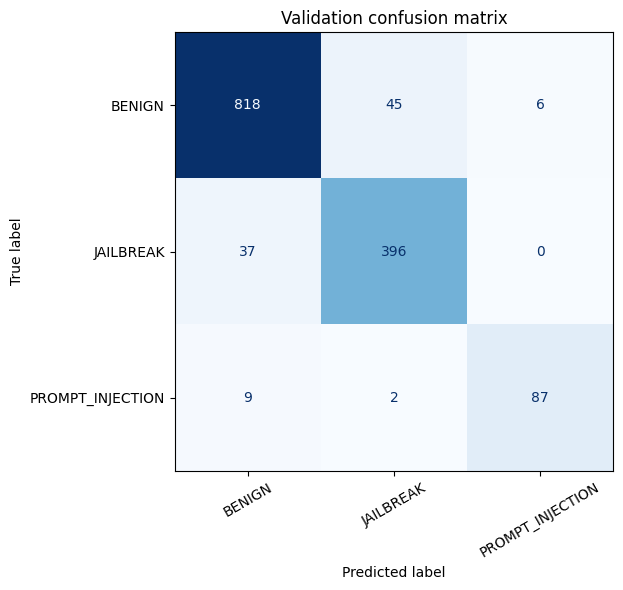

In [13]:
valid_result = trainer.predict(valid_dataset, metric_key_prefix="validation")
valid_logits = valid_result.predictions
if isinstance(valid_logits, tuple):
    valid_logits = valid_logits[0]
if not np.isfinite(valid_logits).all():
    raise ValueError("Validation logits co NaN/Inf; kiem tra training.")
valid_pred = np.argmax(valid_logits, axis=-1)
valid_true = valid_df["label_id"].to_numpy()
report = classification_report(
    valid_true, valid_pred, labels=list(range(len(LABELS))),
    target_names=LABELS, output_dict=True, zero_division=0,
)
report_df = pd.DataFrame(report).T
display(report_df)
report_df.to_csv(ARTIFACT_DIR / "validation_class_report.csv")

language_rows = []
for language in LANGUAGES:
    mask = valid_df["language"].eq(language).to_numpy()
    if not mask.any():
        continue
    f1_values = f1_score(
        valid_true[mask], valid_pred[mask], labels=list(range(len(LABELS))),
        average=None, zero_division=0,
    )
    row = {"language": language, "rows": int(mask.sum()), "macro_f1": float(f1_values.mean())}
    row.update({f"f1_{label}": float(score) for label, score in zip(LABELS, f1_values)})
    language_rows.append(row)
language_report = pd.DataFrame(language_rows)
display(language_report)
language_report.to_csv(ARTIFACT_DIR / "validation_by_language.csv", index=False)

validation_predictions = valid_df[["id", "language", "label"]].copy()
validation_predictions["predicted_label"] = [ID2LABEL[int(value)] for value in valid_pred]
validation_predictions.to_csv(ARTIFACT_DIR / "validation_predictions.csv", index=False)

matrix = confusion_matrix(valid_true, valid_pred, labels=list(range(len(LABELS))))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(
    ax=ax, values_format="d", cmap="Blues", xticks_rotation=30, colorbar=False,
)
ax.set_title("Validation confusion matrix")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "validation_confusion_matrix.png", dpi=150)
plt.show()
plt.close(fig)

np.save(ARTIFACT_DIR / "validation_logits.npy", valid_logits.astype(np.float32))
valid_df[["id", "language", "label"]].to_csv(ARTIFACT_DIR / "validation_ids.csv", index=False)
raw_errors = valid_df[["id", "language", "label", "text"]].copy()
raw_errors["predicted_label"] = [ID2LABEL[int(i)] for i in valid_pred]
raw_errors["raw_tokens"] = valid_dataset.raw_lengths
raw_errors["truncated"] = raw_errors["raw_tokens"] > budget
raw_errors.loc[valid_true != valid_pred].to_csv(ARTIFACT_DIR / "validation_errors_raw.csv", index=False)


## 10. Dự đoán test và xuất submission

Dự đoán giữ liên kết với test ID, sau đó sắp theo **sample_submission.csv**. File nộp chỉ có hai cột **id,label** và đúng 6.000 dòng. Nhãn mẫu không ảnh hưởng dự đoán.


In [14]:
test_result = trainer.predict(test_dataset, metric_key_prefix="test")
test_logits = test_result.predictions
if isinstance(test_logits, tuple):
    test_logits = test_logits[0]
if test_logits.shape != (len(test_df), len(LABELS)) or not np.isfinite(test_logits).all():
    raise ValueError("Test logits sai shape hoac co NaN/Inf.")
np.save(ARTIFACT_DIR / "test_logits.npy", test_logits.astype(np.float32))
test_df[["id", "language"]].to_csv(ARTIFACT_DIR / "test_ids.csv", index=False)
print("Da luu logits va ID order. Cell sau chon ensemble/bias tu validation.")


Da luu logits va ID order. Cell sau chon ensemble/bias tu validation.


### Chọn ensemble và bias

Tìm một tập nhỏ trọng số trộn/temperature và bias toàn cục trên validation.
Cross-fit 3 phần của validation: fit hậu xử lý trên 2 phần, dự đoán phần còn lại.
Chỉ dùng hậu xử lý khi Macro F1 cross-fit tăng ít nhất MIN_POSTPROCESS_GAIN so với QLoRA thô.
Sau guard, fit cấu hình cuối trên toàn validation và áp dụng cùng cấu hình lên test.

**Giới hạn:** checkpoint và các cấu hình đã được chọn bằng cùng validation; cross-fit ở đây chỉ kiểm tra
hậu xử lý, không thay cho outer CV độc lập. Điểm fitted phải ghi riêng, không gọi là điểm private/test.
Không tune bias riêng cho từng ngôn ngữ vì nhóm English injection chỉ khoảng 10 mẫu.


In [15]:
"""Conservative post-processing cell for the RMIT C1 notebook.

Paste this file into one notebook code cell after ``valid_logits`` and
``test_logits`` exist. If the lexical SVM is enabled, its decision-function
outputs must be named ``valid_lexical_scores`` and ``test_lexical_scores`` and
must already use the same class order as ``LABELS``.

This cell deliberately performs no artifact I/O. The notebook's artifact cell
should save the returned configuration, report, predictions, and source logits.
"""

from __future__ import annotations

from itertools import product
from typing import Any, Iterable, Mapping, Optional, Sequence

import numpy as np
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold


EXPECTED_POSTPROCESS_LABELS = ["BENIGN", "JAILBREAK", "PROMPT_INJECTION"]


def _as_score_matrix(name: str, values: Any, rows: Optional[int] = None) -> np.ndarray:
    """Return a finite float64 (rows, 3) score matrix."""
    matrix = np.asarray(values, dtype=np.float64)
    if matrix.ndim != 2 or matrix.shape[1] != len(EXPECTED_POSTPROCESS_LABELS):
        raise ValueError(
            f"{name} must have shape (n, {len(EXPECTED_POSTPROCESS_LABELS)}); "
            f"received {matrix.shape}."
        )
    if rows is not None and matrix.shape[0] != rows:
        raise ValueError(f"{name} must have {rows} rows; received {matrix.shape[0]}.")
    if not np.isfinite(matrix).all():
        raise ValueError(f"{name} contains NaN or Inf.")
    return matrix


def log_softmax_np(scores: np.ndarray, temperature: float = 1.0) -> np.ndarray:
    """Numerically stable log-softmax for a small dense score matrix."""
    temperature = float(temperature)
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("temperature must be finite and positive.")
    scaled = np.asarray(scores, dtype=np.float64) / temperature
    shifted = scaled - scaled.max(axis=1, keepdims=True)
    return shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))


def softmax_from_log_scores(log_scores: np.ndarray) -> np.ndarray:
    """Normalize arbitrary log-scores into probabilities."""
    values = np.asarray(log_scores, dtype=np.float64)
    shifted = values - values.max(axis=1, keepdims=True)
    probabilities = np.exp(shifted)
    probabilities /= probabilities.sum(axis=1, keepdims=True)
    return probabilities


def macro_f1(y_true: np.ndarray, y_pred: np.ndarray, class_count: int = 3) -> float:
    """Macro F1 with all competition classes present in the metric."""
    return float(
        f1_score(
            np.asarray(y_true, dtype=np.int64),
            np.asarray(y_pred, dtype=np.int64),
            labels=np.arange(class_count),
            average="macro",
            zero_division=0,
        )
    )


def postprocess_log_scores(
    neural_logits: np.ndarray,
    lexical_scores: Optional[np.ndarray],
    config: Mapping[str, Any],
) -> np.ndarray:
    """Apply a fitted temperature/blend/bias configuration."""
    neural_log_proba = log_softmax_np(
        neural_logits, float(config["neural_temperature"])
    )
    lexical_weight = float(config.get("lexical_weight", 0.0))
    if lexical_weight > 0:
        if lexical_scores is None:
            raise ValueError("The fitted configuration requires lexical scores.")
        lexical_log_proba = log_softmax_np(
            lexical_scores, float(config["lexical_temperature"])
        )
        combined = (
            (1.0 - lexical_weight) * neural_log_proba
            + lexical_weight * lexical_log_proba
        )
    else:
        combined = neural_log_proba

    bias = np.asarray(config.get("class_bias", [0.0, 0.0, 0.0]), dtype=np.float64)
    if bias.shape != (neural_log_proba.shape[1],) or not np.isfinite(bias).all():
        raise ValueError("class_bias has an invalid shape or value.")
    return combined + bias[None, :]


def _config_simplicity_key(config: Mapping[str, Any]) -> tuple[Any, ...]:
    """Prefer no bias, then neural-only, then values closest to identity."""
    bias = np.asarray(config["class_bias"], dtype=np.float64)
    bias_norm = float(np.dot(bias, bias))
    lexical_weight = float(config["lexical_weight"])
    lexical_temperature = config.get("lexical_temperature")
    return (
        int(bias_norm > 1e-15),
        int(lexical_weight > 1e-15),
        bias_norm,
        lexical_weight,
        abs(float(np.log(float(config["neural_temperature"])))),
        0.0
        if lexical_temperature is None
        else abs(float(np.log(float(lexical_temperature)))),
    )


def fit_postprocessor(
    neural_logits: np.ndarray,
    y_true: np.ndarray,
    lexical_scores: Optional[np.ndarray] = None,
    *,
    neural_temperatures: Sequence[float] = (1.0, 2.0),
    lexical_temperatures: Sequence[float] = (0.5, 1.0),
    lexical_weights: Sequence[float] = (0.0, 0.25, 0.50, 0.75, 0.90),
    bias_values: Sequence[float] = (-0.30, -0.15, 0.0, 0.15, 0.30),
    bias_l2: float = 0.002,
    tie_tolerance: float = 1e-12,
) -> dict[str, Any]:
    """Fit a small global post-processing grid on the supplied rows.

    BENIGN bias is fixed to zero because adding the same constant to all class
    scores cannot change a prediction. Only two bias coordinates are searched.
    Candidate matrices are evaluated one at a time to keep memory bounded.
    """
    neural_logits = _as_score_matrix("neural_logits", neural_logits)
    y_true = np.asarray(y_true, dtype=np.int64)
    if y_true.shape != (neural_logits.shape[0],):
        raise ValueError("y_true length does not match neural_logits.")
    if not np.isin(y_true, np.arange(neural_logits.shape[1])).all():
        raise ValueError("y_true contains a class outside [0, 2].")
    if lexical_scores is not None:
        lexical_scores = _as_score_matrix(
            "lexical_scores", lexical_scores, neural_logits.shape[0]
        )

    neural_temperatures = tuple(float(value) for value in neural_temperatures)
    lexical_temperatures = tuple(float(value) for value in lexical_temperatures)
    lexical_weights = tuple(float(value) for value in lexical_weights)
    bias_values = tuple(float(value) for value in bias_values)
    if 1.0 not in neural_temperatures or 0.0 not in lexical_weights or 0.0 not in bias_values:
        raise ValueError("The conservative grid must include temperature=1, weight=0, and bias=0.")
    if any(value <= 0 for value in neural_temperatures + lexical_temperatures):
        raise ValueError("All temperatures must be positive.")
    if any(value < 0 or value >= 1 for value in lexical_weights):
        raise ValueError("lexical_weights must be in [0, 1).")
    if bias_l2 < 0:
        raise ValueError("bias_l2 must be nonnegative.")

    neural_cache = {
        temperature: log_softmax_np(neural_logits, temperature)
        for temperature in neural_temperatures
    }
    lexical_cache = (
        {
            temperature: log_softmax_np(lexical_scores, temperature)
            for temperature in lexical_temperatures
        }
        if lexical_scores is not None
        else {}
    )

    best_config: Optional[dict[str, Any]] = None
    best_objective = -np.inf
    best_score = -np.inf
    candidate_count = 0

    for neural_temperature in neural_temperatures:
        neural_log_proba = neural_cache[neural_temperature]
        weights_to_try: Iterable[float] = (
            lexical_weights if lexical_scores is not None else (0.0,)
        )
        for lexical_weight in weights_to_try:
            temperatures_to_try: Iterable[Optional[float]] = (
                (None,) if lexical_weight == 0.0 else lexical_temperatures
            )
            for lexical_temperature in temperatures_to_try:
                if lexical_weight == 0.0:
                    base_scores = neural_log_proba
                else:
                    lexical_log_proba = lexical_cache[float(lexical_temperature)]
                    base_scores = (
                        (1.0 - lexical_weight) * neural_log_proba
                        + lexical_weight * lexical_log_proba
                    )

                for jailbreak_bias, injection_bias in product(bias_values, repeat=2):
                    bias = np.array([0.0, jailbreak_bias, injection_bias], dtype=np.float64)
                    predictions = np.argmax(base_scores + bias[None, :], axis=1)
                    score = macro_f1(y_true, predictions, base_scores.shape[1])
                    bias_norm = float(np.dot(bias, bias))
                    objective = score - float(bias_l2) * bias_norm
                    config = {
                        "neural_temperature": float(neural_temperature),
                        "lexical_temperature": (
                            None if lexical_temperature is None else float(lexical_temperature)
                        ),
                        "lexical_weight": float(lexical_weight),
                        "class_bias": bias.tolist(),
                    }
                    candidate_count += 1

                    is_better = objective > best_objective + tie_tolerance
                    is_tied = abs(objective - best_objective) <= tie_tolerance
                    if is_better or (
                        is_tied
                        and (
                            best_config is None
                            or _config_simplicity_key(config)
                            < _config_simplicity_key(best_config)
                        )
                    ):
                        best_config = config
                        best_objective = float(objective)
                        best_score = float(score)

    if best_config is None:
        raise RuntimeError("Post-processing grid unexpectedly produced no candidate.")
    best_config.update(
        {
            "fit_macro_f1": best_score,
            "penalized_objective": best_objective,
            "bias_l2": float(bias_l2),
            "candidate_count": int(candidate_count),
        }
    )
    return best_config


def cross_fitted_postprocess(
    neural_logits: np.ndarray,
    y_true: np.ndarray,
    strata: np.ndarray,
    lexical_scores: Optional[np.ndarray] = None,
    *,
    n_splits: int = 3,
    random_state: int = 42,
    fit_kwargs: Optional[Mapping[str, Any]] = None,
) -> tuple[np.ndarray, list[dict[str, Any]]]:
    """Select post-processing on two folds and predict the held-out fold."""
    neural_logits = _as_score_matrix("neural_logits", neural_logits)
    y_true = np.asarray(y_true, dtype=np.int64)
    strata = np.asarray(strata, dtype=str)
    if y_true.shape != (neural_logits.shape[0],) or strata.shape != y_true.shape:
        raise ValueError("y_true/strata length does not match neural_logits.")
    if lexical_scores is not None:
        lexical_scores = _as_score_matrix(
            "lexical_scores", lexical_scores, neural_logits.shape[0]
        )

    unique_strata, stratum_counts = np.unique(strata, return_counts=True)
    if len(unique_strata) < neural_logits.shape[1]:
        raise ValueError("Too few strata for cross-fitted post-processing.")
    if int(stratum_counts.min()) < int(n_splits):
        raise ValueError(
            f"Every language::label stratum needs at least {n_splits} rows; "
            f"smallest has {int(stratum_counts.min())}."
        )

    splitter = StratifiedKFold(
        n_splits=int(n_splits), shuffle=True, random_state=int(random_state)
    )
    oof_predictions = np.full(y_true.shape, -1, dtype=np.int64)
    fold_reports: list[dict[str, Any]] = []
    fit_kwargs = dict(fit_kwargs or {})

    for fold, (fit_index, holdout_index) in enumerate(
        splitter.split(np.zeros(y_true.shape[0]), strata), start=1
    ):
        fit_lexical = None if lexical_scores is None else lexical_scores[fit_index]
        holdout_lexical = None if lexical_scores is None else lexical_scores[holdout_index]
        config = fit_postprocessor(
            neural_logits[fit_index],
            y_true[fit_index],
            fit_lexical,
            **fit_kwargs,
        )
        holdout_log_scores = postprocess_log_scores(
            neural_logits[holdout_index], holdout_lexical, config
        )
        holdout_predictions = np.argmax(holdout_log_scores, axis=1)
        oof_predictions[holdout_index] = holdout_predictions
        raw_predictions = np.argmax(neural_logits[holdout_index], axis=1)
        raw_score = macro_f1(y_true[holdout_index], raw_predictions)
        post_score = macro_f1(y_true[holdout_index], holdout_predictions)
        fold_reports.append(
            {
                "fold": int(fold),
                "fit_rows": int(fit_index.size),
                "holdout_rows": int(holdout_index.size),
                "holdout_raw_neural_macro_f1": raw_score,
                "holdout_postprocess_macro_f1": post_score,
                "holdout_gain": float(post_score - raw_score),
                "selected_config": config,
            }
        )

    if (oof_predictions < 0).any():
        raise RuntimeError("Some validation rows did not receive a cross-fitted prediction.")
    return oof_predictions, fold_reports


def run_postprocessing(
    valid_logits: np.ndarray,
    test_logits: np.ndarray,
    valid_df: Any,
    labels: Sequence[str],
    valid_lexical_scores: Optional[np.ndarray] = None,
    test_lexical_scores: Optional[np.ndarray] = None,
    *,
    split_seed: int = 42,
    min_postprocess_gain: float = 0.002,
    n_splits: int = 3,
    fit_kwargs: Optional[Mapping[str, Any]] = None,
) -> dict[str, Any]:
    """Run cross-fitted selection, its safety gate, and final all-valid fit."""
    if list(labels) != EXPECTED_POSTPROCESS_LABELS:
        raise ValueError(
            f"LABELS must be exactly {EXPECTED_POSTPROCESS_LABELS}; received {list(labels)}."
        )
    valid_logits = _as_score_matrix("valid_logits", valid_logits, len(valid_df))
    test_logits = _as_score_matrix("test_logits", test_logits)
    if min_postprocess_gain < 0:
        raise ValueError("min_postprocess_gain must be nonnegative.")

    lexical_enabled = valid_lexical_scores is not None or test_lexical_scores is not None
    if lexical_enabled and (valid_lexical_scores is None or test_lexical_scores is None):
        raise ValueError(
            "valid_lexical_scores and test_lexical_scores must both be provided or both be None."
        )
    if lexical_enabled:
        valid_lexical_scores = _as_score_matrix(
            "valid_lexical_scores", valid_lexical_scores, valid_logits.shape[0]
        )
        test_lexical_scores = _as_score_matrix(
            "test_lexical_scores", test_lexical_scores, test_logits.shape[0]
        )

    required_columns = {"id", "language", "label_id"}
    missing_columns = required_columns - set(valid_df.columns)
    if missing_columns:
        raise ValueError(f"valid_df is missing columns: {sorted(missing_columns)}.")
    if valid_df["id"].duplicated().any():
        raise ValueError("valid_df IDs must be unique.")
    y_true = valid_df["label_id"].to_numpy(dtype=np.int64)
    if not np.isin(y_true, np.arange(len(labels))).all():
        raise ValueError("valid_df.label_id contains a class outside [0, 2].")
    languages = valid_df["language"].astype(str).to_numpy()
    strata = np.asarray(
        [f"{language}::{label_id}" for language, label_id in zip(languages, y_true)],
        dtype=str,
    )

    raw_valid_pred = np.argmax(valid_logits, axis=1)
    raw_macro = macro_f1(y_true, raw_valid_pred, len(labels))
    oof_predictions, fold_reports = cross_fitted_postprocess(
        valid_logits,
        y_true,
        strata,
        valid_lexical_scores,
        n_splits=n_splits,
        random_state=split_seed,
        fit_kwargs=fit_kwargs,
    )
    oof_macro = macro_f1(y_true, oof_predictions, len(labels))
    oof_gain = float(oof_macro - raw_macro)
    gate_passed = bool(oof_gain >= float(min_postprocess_gain))

    shared_validation_warning = (
        "Cross-fitting protects the post-processing comparison from fitting and scoring each "
        "bias/blend on the same rows. It is still not an independent model estimate because "
        "the checkpoint and other hyperparameters were selected using this validation set."
    )
    all_valid_fit_warning = (
        "The all-validation tuned Macro F1 is an in-sample diagnostic only; use the "
        "cross-fitted score for the post-processing gate."
    )

    if gate_passed:
        fitted_config = fit_postprocessor(
            valid_logits,
            y_true,
            valid_lexical_scores,
            **dict(fit_kwargs or {}),
        )
        final_valid_log_scores = postprocess_log_scores(
            valid_logits, valid_lexical_scores, fitted_config
        )
        final_test_log_scores = postprocess_log_scores(
            test_logits, test_lexical_scores, fitted_config
        )
        final_valid_proba = softmax_from_log_scores(final_valid_log_scores)
        final_test_proba = softmax_from_log_scores(final_test_log_scores)
        final_valid_pred = np.argmax(final_valid_proba, axis=1)
        final_test_pred = np.argmax(final_test_proba, axis=1)
        full_valid_macro = macro_f1(y_true, final_valid_pred, len(labels))
        postprocess_config = {
            "enabled": True,
            "mode": "global_log_probability_blend_and_bias",
            "lexical_enabled": bool(lexical_enabled),
            "minimum_oof_gain": float(min_postprocess_gain),
            "parameters": fitted_config,
        }
    else:
        final_valid_log_scores = log_softmax_np(valid_logits, 1.0)
        final_test_log_scores = log_softmax_np(test_logits, 1.0)
        final_valid_proba = np.exp(final_valid_log_scores)
        final_test_proba = np.exp(final_test_log_scores)
        final_valid_pred = raw_valid_pred.copy()
        final_test_pred = np.argmax(test_logits, axis=1)
        full_valid_macro = raw_macro
        postprocess_config = {
            "enabled": False,
            "mode": "raw_neural",
            "lexical_enabled": bool(lexical_enabled),
            "minimum_oof_gain": float(min_postprocess_gain),
            "parameters": {
                "neural_temperature": 1.0,
                "lexical_temperature": None,
                "lexical_weight": 0.0,
                "class_bias": [0.0, 0.0, 0.0],
            },
        }

    selection_report = {
        "gate_passed": gate_passed,
        "lexical_enabled": bool(lexical_enabled),
        "validation_rows": int(valid_logits.shape[0]),
        "cross_fit_folds": int(n_splits),
        "raw_neural_macro_f1": raw_macro,
        "cross_fitted_postprocess_macro_f1": oof_macro,
        "cross_fitted_gain": oof_gain,
        "minimum_required_gain": float(min_postprocess_gain),
        "all_validation_tuned_macro_f1": full_valid_macro,
        "folds": fold_reports,
        "warnings": [shared_validation_warning, all_valid_fit_warning],
        "language_specific_bias": False,
    }

    return {
        "final_valid_pred": final_valid_pred,
        "final_test_pred": final_test_pred,
        "final_valid_proba": final_valid_proba,
        "final_test_proba": final_test_proba,
        "final_valid_scores": final_valid_log_scores,
        "final_test_scores": final_test_log_scores,
        "postprocess_oof_pred": oof_predictions,
        "POSTPROCESS_CONFIG": postprocess_config,
        "POSTPROCESS_SELECTION_REPORT": selection_report,
    }


# When pasted as a notebook cell, publish the requested variables. Importing
# this file as a module does not execute the notebook-specific branch.
_required_notebook_names = {"valid_logits", "test_logits", "valid_df", "LABELS"}
if _required_notebook_names.issubset(globals()):
    MIN_POSTPROCESS_GAIN = float(globals().get("MIN_POSTPROCESS_GAIN", 0.002))
    POSTPROCESS_SPLIT_SEED = int(
        globals().get("SPLIT_SEED", globals().get("SEED", 42))
    )
    _postprocess_result = run_postprocessing(
        valid_logits=globals()["valid_logits"],
        test_logits=globals()["test_logits"],
        valid_df=globals()["valid_df"],
        labels=globals()["LABELS"],
        valid_lexical_scores=globals().get("valid_lexical_scores"),
        test_lexical_scores=globals().get("test_lexical_scores"),
        split_seed=POSTPROCESS_SPLIT_SEED,
        min_postprocess_gain=MIN_POSTPROCESS_GAIN,
        n_splits=3,
    )
    globals().update(_postprocess_result)
    print(
        "Post-processing:",
        "enabled" if POSTPROCESS_CONFIG["enabled"] else "raw neural retained",
        "| raw Macro F1 =",
        round(POSTPROCESS_SELECTION_REPORT["raw_neural_macro_f1"], 6),
        "| cross-fitted Macro F1 =",
        round(POSTPROCESS_SELECTION_REPORT["cross_fitted_postprocess_macro_f1"], 6),
        "| gain =",
        round(POSTPROCESS_SELECTION_REPORT["cross_fitted_gain"], 6),
    )

POSTPROCESS_SELECTION_REPORT["raw_lexical_macro_f1"] = (
    macro_f1(valid_true, valid_lexical_scores.argmax(axis=1))
    if valid_lexical_scores is not None else None
)
POSTPROCESS_CONFIG["labels"] = list(LABELS)
POSTPROCESS_CONFIG["score_interpretation"] = (
    "Normalized tempered log-score blend, tuned for Macro F1; not calibrated confidence."
)
POSTPROCESS_CONFIG["search_grid"] = {
    "neural_temperatures": [1.0, 2.0], "lexical_temperatures": [0.5, 1.0],
    "lexical_weights": [0.0, 0.25, 0.50, 0.75, 0.90],
    "bias_values": [-0.30, -0.15, 0.0, 0.15, 0.30], "bias_l2": 0.002,
}
print("Final parameters:", POSTPROCESS_CONFIG["parameters"])


Post-processing: enabled | raw Macro F1 = 0.919711 | cross-fitted Macro F1 = 0.952069 | gain = 0.032358
Final parameters: {'neural_temperature': 2.0, 'lexical_temperature': 0.5, 'lexical_weight': 0.5, 'class_bias': [0.0, -0.3, 0.3], 'fit_macro_f1': 0.9584021294059385, 'penalized_objective': 0.9580421294059385, 'bias_l2': 0.002, 'candidate_count': 450}


### Xuất CSV và báo cáo cuối

`submission.csv` là output chính; `submission_distilbert_raw.csv` giữ dự đoán QLoRA để đối chiếu.


In [16]:
def validate_submission(frame, expected_test, template):
    assert list(frame.columns) == ["id", "label"], "Sai cot submission."
    assert len(frame) == len(expected_test) == 6000, "Sai so dong."
    assert frame["id"].is_unique, "ID trung."
    assert frame.notna().all().all(), "Submission co gia tri thieu."
    assert set(frame["id"]) == set(expected_test["id"]), "Thieu/thua ID."
    assert frame["id"].tolist() == template["id"].tolist(), "Sai thu tu sample."
    assert frame["label"].isin(LABELS).all(), "Nhan khong hop le."

def make_submission(predicted, destination):
    assert len(predicted) == len(test_df)
    predictions = pd.DataFrame({"id": test_df["id"].to_numpy(),
                                "label": [ID2LABEL[int(i)] for i in predicted]})
    result = sample_df[["id"]].merge(predictions, on="id", how="left", sort=False, validate="one_to_one")
    validate_submission(result, test_df, sample_df)
    result.to_csv(destination, index=False, encoding="utf-8")
    validate_submission(pd.read_csv(destination, dtype=str, keep_default_na=False), test_df, sample_df)
    return result

# Giu CSV QLoRA rieng de so sanh; CSV chinh theo postprocess guard.
make_submission(test_logits.argmax(axis=1), ARTIFACT_DIR / "submission_distilbert_raw.csv")
SUBMISSION_PATH = Path("/content/submission.csv")
submission = make_submission(final_test_pred, SUBMISSION_PATH)
shutil.copy2(SUBMISSION_PATH, ARTIFACT_DIR / "submission.csv")

final_report = pd.DataFrame(classification_report(
    valid_true, final_valid_pred, labels=np.arange(len(LABELS)), target_names=LABELS,
    output_dict=True, zero_division=0,
)).T
print("Final fitted validation report (selection set, NOT an independent score):")
display(final_report)
final_report.to_csv(ARTIFACT_DIR / "validation_final_fitted_report.csv")
final_language_rows = []
for language in LANGUAGES:
    mask = valid_df["language"].eq(language).to_numpy()
    scores = f1_score(valid_true[mask], final_valid_pred[mask], labels=np.arange(len(LABELS)),
                      average=None, zero_division=0)
    row = {"language": language, "rows": int(mask.sum()), "macro_f1": float(scores.mean())}
    row.update({f"f1_{label}": float(s) for label, s in zip(LABELS, scores)})
    final_language_rows.append(row)
pd.DataFrame(final_language_rows).to_csv(ARTIFACT_DIR / "validation_final_by_language.csv", index=False)
final_matrix = confusion_matrix(valid_true, final_valid_pred, labels=np.arange(len(LABELS)))
pd.DataFrame(final_matrix, index=LABELS, columns=LABELS).to_csv(ARTIFACT_DIR / "validation_final_confusion.csv")
final_errors = raw_errors.copy()
final_errors["predicted_label"] = [ID2LABEL[int(i)] for i in final_valid_pred]
final_errors.loc[valid_true != final_valid_pred].to_csv(ARTIFACT_DIR / "validation_errors_final.csv", index=False)
final_valid_rows = valid_df[["id", "language", "label"]].copy()
final_valid_rows["predicted_label"] = [ID2LABEL[int(i)] for i in final_valid_pred]
final_valid_rows.to_csv(ARTIFACT_DIR / "validation_final_predictions.csv", index=False)
np.save(ARTIFACT_DIR / "test_final_probabilities.npy", final_test_proba)
(ARTIFACT_DIR / "postprocess.json").write_text(
    json.dumps(POSTPROCESS_CONFIG, indent=2, ensure_ascii=False), encoding="utf-8")
(ARTIFACT_DIR / "postprocess_selection.json").write_text(
    json.dumps(POSTPROCESS_SELECTION_REPORT, indent=2, ensure_ascii=False), encoding="utf-8")
oof_report = valid_df[["id", "language", "label"]].copy()
oof_report["predicted_label"] = [ID2LABEL[int(i)] for i in postprocess_oof_pred]
oof_report.to_csv(ARTIFACT_DIR / "validation_postprocess_crossfit.csv", index=False)
display(submission.head())
display(submission["label"].value_counts().reindex(LABELS, fill_value=0))
print("Submission:", SUBMISSION_PATH)
print("SHA256:", hashlib.sha256(SUBMISSION_PATH.read_bytes()).hexdigest())


Final fitted validation report (selection set, NOT an independent score):


,precision,recall,f1-score,support
BENIGN,0.962372,0.971231,0.966781,869.000000
JAILBREAK,0.944056,0.935335,0.939675,433.000000
PROMPT_INJECTION,0.989362,0.948980,0.968750,98.000000
accuracy,0.958571,0.958571,0.958571,0.958571
macro avg,0.965263,0.951849,0.958402,1400.000000
weighted avg,0.958596,0.958571,0.958536,1400.000000


,id,label
0,t000006,BENIGN
1,t000007,BENIGN
2,t000008,PROMPT_INJECTION
3,t000017,JAILBREAK
4,t000019,BENIGN


,count
label,
BENIGN,3821
JAILBREAK,1792
PROMPT_INJECTION,387


Submission: /content/submission.csv
SHA256: a3f1037a7110fa1aaaa78356626eceb72f71c7801a928a6133937fca637d55d2


## 11. Lưu cấu hình và đóng gói

ZIP gồm adapter + heads, tokenizer, lexical.joblib (nếu bật), postprocess.json,
logits/ID order, báo cáo, split, cấu hình và CSV. Muốn tái tạo ensemble cần cả nhánh SVM và postprocess.
Base model không đóng gói lại; dùng đúng revision. Chỉ nạp file joblib do bạn tạo.
Checkpoints chứa optimizer ở RUN_DIR/checkpoints để resume; không gộp vào ZIP.
Model train trên fit split 12.600 dòng. Validation được dùng chọn checkpoint/cấu hình, không phải final test.


In [17]:
run_config = {
    "team": "RMIT_SGS_Sigma69_C1",
    "run_id": RUN_ID,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "model_source": MODEL_SOURCE,
    "requested_revision": MODEL_REVISION,
    "resolved_model_revision": RESOLVED_MODEL_REVISION,
    "labels": LABELS,
    "label2id": LABEL2ID,
    "seed": SEED,
    "split_seed": SPLIT_SEED,
    "notebook_version": "v2",
    "validation_size": VAL_SIZE,
    "training_rows": len(fit_df),
    "validation_rows": len(valid_df),
    "test_rows": len(test_df),
    "max_length": MAX_LENGTH,
    "long_text_mode": LONG_TEXT_MODE,
    "epochs_requested": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
    "effective_batch_size": TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS,
    "class_weights": weight_values.tolist(),
    "class_weight_power": power,
    "postprocess": POSTPROCESS_CONFIG,
    "lexical": {"enabled": ENABLE_LEXICAL_BRANCH, "analyzer": "char_wb",
                "ngram_range": [2, 6], "C": LEXICAL_C, "class_weight": "balanced",
                "min_df": 2, "sublinear_tf": True, "max_features": LEXICAL_MAX_FEATURES,
                "global_weight": LEXICAL_GLOBAL_WEIGHT},
    "loss": "power_frequency_weighted_cross_entropy_mean_over_samples" if USE_CLASS_WEIGHTS else "cross_entropy",
    "quantization": {
        "load_in_4bit": True, "quant_type": "nf4", "double_quant": True,
        "compute_dtype": str(COMPUTE_DTYPE), "skip_modules": HEAD_MODULES,
    },
    "lora": {
        "rank": LORA_R, "alpha": LORA_ALPHA, "dropout": LORA_DROPOUT,
        "target_modules": LORA_TARGETS, "modules_to_save": HEAD_MODULES,
    },
    "gpu": torch.cuda.get_device_name(0),
    "gpu_capability": list(GPU_CAPABILITY),
    "package_versions": PACKAGE_VERSIONS,
    "data_sha256": DATA_HASHES,
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "best_validation_macro_f1": trainer.state.best_metric,
    "baseline_validation_macro_f1": 0.8863657407407408,
    "baseline_public_score_user_reported": 0.87,
    "submission_sha256": hashlib.sha256(SUBMISSION_PATH.read_bytes()).hexdigest(),
}
(ARTIFACT_DIR / "run_config.json").write_text(
    json.dumps(run_config, indent=2, ensure_ascii=False), encoding="utf-8",
)
(ARTIFACT_DIR / "label_mapping.json").write_text(
    json.dumps({"label2id": LABEL2ID, "id2label": ID2LABEL}, indent=2), encoding="utf-8",
)
(ARTIFACT_DIR / "validation_metrics.json").write_text(
    json.dumps(valid_result.metrics, indent=2), encoding="utf-8",
)
(ARTIFACT_DIR / "training_arguments.json").write_text(
    training_args.to_json_string(), encoding="utf-8",
)
(ARTIFACT_DIR / "training_log.json").write_text(
    json.dumps(trainer.state.log_history, indent=2), encoding="utf-8",
)
(ARTIFACT_DIR / "requirements-used.txt").write_text(
    "\n".join(f"{name}=={release}" for name, release in PACKAGE_VERSIONS.items()) + "\n",
    encoding="utf-8",
)
ARCHIVE_PATH = Path(shutil.make_archive(
    str(RUN_DIR / "rmit_c1_artifacts"), "zip", root_dir=str(ARTIFACT_DIR),
))
print("Artifacts:", ARTIFACT_DIR)
print("ZIP:", ARCHIVE_PATH, f"({ARCHIVE_PATH.stat().st_size / 2**20:.1f} MiB)")
PUBLIC_ARCHIVE_PATH = Path("/content/rmit_c1_artifacts.zip")
if ARCHIVE_PATH.resolve() != PUBLIC_ARCHIVE_PATH.resolve():
    shutil.copy2(ARCHIVE_PATH, PUBLIC_ARCHIVE_PATH)
print("Files panel download:", PUBLIC_ARCHIVE_PATH)


Artifacts: /content/rmit_c1_runs/distilmbert_qlora_v2_20261022T061310_050585Z/artifacts
ZIP: /content/rmit_c1_runs/distilmbert_qlora_v2_20261022T061310_050585Z/rmit_c1_artifacts.zip (25.7 MiB)
Files panel download: /content/rmit_c1_artifacts.zip


## 12. Tải kết quả

Mở panel **Files** bên trái Colab → Refresh → `submission.csv` → dấu ba chấm → **Download**.
ZIP `rmit_c1_artifacts.zip` cùng thư mục `/content` chứa model và báo cáo; chỉ CSV dùng để nộp dự đoán.
Không cần chạy lại train nếu trình duyệt chặn download. Hai cell dưới chỉ in đường dẫn;
đặt cờ `True` và chạy riêng một cell nếu muốn thử tải tự động.


In [18]:
DOWNLOAD_CSV_NOW = False
print("Files panel: /content/submission.csv")
print("Size:", SUBMISSION_PATH.stat().st_size, "bytes")
if DOWNLOAD_CSV_NOW:
    from google.colab import files
    files.download(str(SUBMISSION_PATH))


Files panel: /content/submission.csv
Size: 99255 bytes


In [19]:
DOWNLOAD_ZIP_NOW = False
print("Files panel:", PUBLIC_ARCHIVE_PATH)
if DOWNLOAD_ZIP_NOW:
    from google.colab import files
    files.download(str(PUBLIC_ARCHIVE_PATH))


Files panel: /content/rmit_c1_artifacts.zip


## Tài liệu đối chiếu

- [Đề bài và submission](https://www.kaggle.com/competitions/rmit-hackathon-2026/overview)
- [DistilBERT multilingual](https://huggingface.co/distilbert/distilbert-base-multilingual-cased)
- [PEFT LoRA config](https://huggingface.co/docs/peft/v0.17.0/package_reference/lora)
- [Transformers Trainer 4.57](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer)
- [PyTorch BF16 support](https://docs.pytorch.org/docs/stable/generated/torch.cuda.is_bf16_supported.html)
- [LinearSVC 1.6.1](https://scikit-learn.org/1.6/modules/generated/sklearn.svm.LinearSVC.html)

Mục tiêu 0.95 là mục tiêu thử nghiệm. Notebook v2 cần chạy trên GPU trước khi có thể đánh giá kết quả.
Không suy ra điểm Kaggle từ kết quả tuning trên validation.
